# 6. DFTHC resource estimation for FeMoco

In tutorial 4, we built a qubitisation walk operator from the Pauli decomposition of a Hamiltonian. That approach doesn't scale to industrially relevant molecules: the number of Pauli terms grows as $N^4$, and so does the cost of the block encoding. State-of-the-art estimates instead compress the two-electron integrals with a tensor factorisation and build a bespoke block encoding for the factorised form.

In this tutorial, we follow [[Low et al. (2025)](https://doi.org/10.1103/pb2g-j9cw)], who introduced the **double-factorised tensor hypercontraction (DFTHC)** representation and combined it with **spectral amplification (SA)**. We reproduce their Toffoli count estimate for the ground-state energy calculation of the 54-orbital active space of FeMoco, the iron-molybdenum cofactor of nitrogenase [[Reiher et al. (2017)](https://doi.org/10.1073/pnas.1619152114)], using quantum phase estimation (QPE).

## 6.1. Background

### The DFTHC Hamiltonian

The spin-free electronic structure Hamiltonian over $N$ spatial orbitals is

$$H = \sum_{pq} h^{(1)}_{pq} E_{pq} + \frac{1}{2}\sum_{pqrs} h^{(2)}_{pqrs} E_{pq} E_{rs}, \qquad E_{pq} = \sum_{\sigma} a^\dagger_{p\sigma} a_{q\sigma}.$$

DFTHC approximates the two-body tensor $h^{(2)}$ as a sum of squares of one-body operators ([Low et al. (2025)](https://doi.org/10.1103/pb2g-j9cw), Eq. 24):

$$h^{(2)}_{pqrs} \approx \sum_{r'=1}^{R}\sum_{c=1}^{C} \Big(\sum_{b=1}^{B} w^{(r'c)}_b\, u^{(r')}_{b,p} u^{(r')}_{b,q}\Big)\Big(\sum_{b'=1}^{B} w^{(r'c)}_{b'}\, u^{(r')}_{b',r} u^{(r')}_{b',s}\Big),$$

with three size parameters:

- **Rank $R$**: the number of independent sets of basis vectors.
- **Bases $B$**: the number of unit vectors $\vec u^{(r)}_b \in \mathbb{R}^N$ in each set.
- **Copies $C$**: the number of weight vectors $\vec w^{(rc)}$ that reuse the same basis set.

DFTHC interpolates between the two leading factorisations. Double factorisation (DF) [[von Burg et al. (2021)](https://doi.org/10.1103/PhysRevResearch.3.033055)] is the special case $(R, B, C) = (R, N, 1)$ with orthonormal $\vec u$, and tensor hypercontraction (THC) [[Lee et al. (2021)](https://doi.org/10.1103/PRXQuantum.2.030305)] is the special case $(1, R_{\mathrm{THC}}, R_{\mathrm{THC}})$. The factorisation is combined with a BLISS symmetry shift (Loaiza and Izmaylov, J. Chem. Theory Comput. 19, 8201 (2023)), which adds terms that vanish in the target electron-number sector to reduce the normalisation.

### Spectral amplification

The cost of QPE is the number of calls to the walk operator, multiplied by the cost of one call. For standard qubitisation, the number of calls to estimate the energy with standard deviation $\sigma_{\mathrm{PEA}}$ is $\lceil \pi\lambda / (2\sigma_{\mathrm{PEA}}) \rceil$ [[Babbush et al. (2018)](https://doi.org/10.1103/PhysRevX.8.041015)], where $\lambda$ is the normalisation of the block encoding.

Because DFTHC writes the Hamiltonian as a sum of squares, $H = H_{\mathrm{sqrt}}^\dagger H_{\mathrm{sqrt}} + E_{\mathrm{SOS}}$, the block encoding has normalisation $\Lambda$ (Eq. 33) and the lowest eigenvalue of $H - E_{\mathrm{SOS}}$ is a small gap $E_{\mathrm{gap}} \ll \Lambda$. Low et al. show that phase estimation on this walk operator then only needs an *effective* normalisation (Eq. 11)

$$\lambda_{\mathrm{eff}} = \sqrt{E_{\mathrm{gap}}\,(2\Lambda - E_{\mathrm{gap}})} \approx \sqrt{2\Lambda E_{\mathrm{gap}}},$$

because the $\arccos$ in the walk operator's eigenphase is steepest near the bottom of the spectrum. The total cost is therefore

$$\text{Toffolis} = \left\lceil \frac{\pi \lambda_{\mathrm{eff}}}{2\sigma_{\mathrm{PEA}}} \right\rceil \times \mathrm{Cost}[\mathrm{BE}],$$

where $\mathrm{Cost}[\mathrm{BE}]$ is the Toffoli cost of one walk step.

### What QUICHE computes

The two factors in the formula come from different places:

- $\mathrm{Cost}[\mathrm{BE}]$ depends only on the *shape* of the factorisation, $(N, R, B, C)$, and on circuit parameters such as bits of precision. QUICHE builds the full circuit as a Qualtran bloq (`DFTHCWalkOperator`) and counts its gates.
- $\Lambda$ and $E_{\mathrm{gap}}$ depend on the *values* of the factors, which come from a classical optimisation of the DFTHC ansatz against the true integrals. That optimisation is not implemented in QUICHE. Here we use a dummy Hamiltonian with the right shape, and take $\Lambda$ and $E_{\mathrm{gap}}$ for FeMoco-54 from Table V of Low et al. (2025).

## 6.2. Setup

We use the FeMoco-54 parameters from Table III of Low et al. (2025). The table below maps each constant to their notation.

| Constant | Symbol | Value | Meaning |
| --- | --- | --- | --- |
| `N` | $N$ | 54 | Number of spatial orbitals (108 system qubits) |
| `R`, `B`, `C` | $R, B, C$ | 10, 27, 27 | DFTHC rank, bases and copies |
| `B_ROT` | $b_{\mathrm{rot}}$ | 15 | Bits per Givens rotation angle, and size of the phase gradient register |
| `B_K1`, `B_K2` | $b_{k1}, b_{k2}$ | 15, 15 | Bits of the keep probabilities in the outer and inner alias sampling |
| `S` | $s$ | 7 | Bits of the amplitude amplification rotation in uniform state preparation |
| `K1`, `K5` | $k_1, k_5$ | 2, 4 | $\log_2$ block size of the outer QROAM and of its uncomputation |
| `K2`, `K4` | $k_2, k_4$ | 4, 2 | $\log_2$ block size of the inner QROAM and of its uncomputation |

The QROAM block sizes trade Toffolis against temporary qubits [[Low, Kliuchnikov and Schaeffer (2018)](https://arxiv.org/abs/1812.00954), [Berry et al. (2019)](https://doi.org/10.22331/q-2019-12-02-208)].

For the phase estimation, we target chemical accuracy with $\sigma_{\mathrm{PEA}} = 1$ mHa, the same choice as Low et al. (2025). The remaining 0.6 mHa of the 1.6 mHa budget for chemical accuracy covers the factorisation error.

In [1]:
from typing import Any

import attrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qualtran import Bloq
from qualtran.resource_counting import (
    GateCounts,
    QECGatesCost,
    QubitCount,
    get_cost_value,
)
from qualtran.surface_code import get_ccz2t_costs_from_grid_search

from quiche.core.electronic import DFTHCHamiltonian
from quiche.resources.bloqs.dfthc import DFTHCWalkOperator

# FeMoco-54 factorisation shape ([Low2025], Table III).
N = 54
R, B, C = 10, 27, 27

# Bits of precision.
B_ROT = 15
B_K1 = B_K2 = 15
S = 7

# log2 of the QROAM block sizes.
K1, K5 = 2, 4  # outer QROAM and its uncomputation
K2, K4 = 4, 2  # inner QROAM and its uncomputation

# Phase estimation target.
SIGMA_PEA = 1e-3  # Hartree
SEED = 0

# Physical assumptions for the surface code cost model (same as tutorial 4).
PHYS_ERR = 1e-3  # physical error rate per operation
CYCLE_TIME_US = 1.0  # surface code cycle time in microseconds
PHYS_ERROR_BUDGET = 1e-2  # allowed failure probability of the whole computation

## 6.3. The DFTHC Hamiltonian

A `DFTHCHamiltonian` stores the factors of Eq. 23 of Low et al. (2025): the unit vectors $u$ with shape $(R, B, N)$, the weights $w$ with shape $(R, B, C)$, and the identity weights $\alpha$ with shape $(R, C)$, which shift each squared factor by a multiple of the identity. It also stores the BLISS matrix and the BLISS constant $\beta_1$ (Eq. 40), the factorised one-body term, a constant and the number of electrons. The identity weights and $\beta_1$ only enter the one-body matrix of the sum-of-squares form (Eq. 26). The eigenvectors of this matrix give the one-body ($D_1/Q_1$) terms of the block encoding.

After optimisation of the factors, the DFTHC Hamiltonian can be read from the database written by the external DFTHC optimiser using `quiche.io.dfthc_db.read(path, job_id)`. Here, we don't have such a database containing the FeMoco factors, so we fill the arrays with random numbers of the right shape.

In [2]:
rng = np.random.default_rng(SEED)

dfthc_ham = DFTHCHamiltonian(
    num_orbitals=N,
    num_ranks=R,
    num_bases=B,
    num_copies=C,
    unit_vectors=rng.normal(size=(R, B, N)),
    weight_vectors=rng.normal(size=(R, B, C)),
    identity_weights=rng.normal(size=(R, C)),
    bliss_matrix=np.zeros((N, N)),
    bliss_constant=0.0,
    factorised_one_body=np.eye(N),
    const=0.0,
    num_electrons=N,
)

## 6.4. Building the walk operator

`DFTHCWalkOperator.from_dfthc_hamiltonian` reads the shape from the Hamiltonian and computes the data of two QROMs, with each Givens rotation angle of `B_ROT` bits. The unit vectors are converted into Givens rotation angles and stored as the data of the rotation QROM (`rotation_data`). The one-body matrix of the sum-of-squares form is diagonalised, and the Givens angles of its eigenvectors, together with the $G_1$ bits that flag the negative eigenvalues, are stored as the data of the inner QROM tail (`tail_data`).

In [3]:
walk_kwargs = {
    "num_bits_keep_inner": B_K2,
    "num_bits_keep_outer": B_K1,
    "num_bits_phase_grad": B_ROT,
    "num_bits_amp_rotations": S,
    "log_block_size_inner": K2,
    "log_block_size_inner_adjoint": K4,
    "log_block_size_outer": K1,
    "log_block_size_outer_adjoint": K5,
}

walk = DFTHCWalkOperator.from_dfthc_hamiltonian(dfthc_ham, **walk_kwargs)
block_encoding = walk.block_encoding
inner = block_encoding.inner

The walk operator is a nested structure, shown in Fig. 2 of Low et al. (2025). The outer state preparation picks one of the $N + RC$ terms of the sum of squares: the $N$ one-body terms ($D_1$/$Q_1$) or one of the $RC$ squared two-body factors (SF). The inner block encoding then encodes that term, and is applied twice around a reflection to square it:

$$
\begin{aligned}
W &= \mathrm{Refl}_{\mathrm{walk}} \cdot \mathrm{OuterPrep}^\dagger \cdot \mathrm{Inner}^\dagger \cdot \mathrm{Refl}_{T_2} \cdot \mathrm{Inner} \cdot \mathrm{OuterPrep}, \\
\mathrm{Inner} &= \mathrm{InnerPrep}^\dagger \cdot \mathrm{RotPrep}^\dagger \cdot \mathrm{Select} \cdot \mathrm{RotPrep} \cdot \mathrm{InnerPrep}.
\end{aligned}
$$

| Bloq | Attribute | What it does |
| --- | --- | --- |
| `OuterPrepareDFTHC` | `block_encoding.outer_prep` | Coherent alias sampling over the $N + RC$ outer terms $x_o$, with a QROAM that outputs the alias sampling data (alt, keep) for the term normalisations $\lambda_{x_o}$ |
| `InnerPrepareDFTHC` | `inner.inner_prep` | Coherent alias sampling over the $B + 1$ inner terms $b$ for the selected $x_o$, with a QROAM over $RC(B+1)$ entries that outputs the alias sampling data (alt, keep, sign) for the weights $w^{(rc)}_b$ |
| `RotationPrepareDFTHC` | `inner.rotation_prep` | QROM that outputs the $(N-1)\,b_{\mathrm{rot}}$ bits of Givens angles that rotate the basis to $\vec u^{(r)}_b$ |
| `SelectDFTHC` | `inner.select` | Applies the Givens rotation ladder with phase gradient additions, the spin-controlled swaps and the Majorana operator to the system register |
| Reflection | `block_encoding.t2_reflection` | Reflection on the inner ancillas between the two inner block encodings, giving the Chebyshev polynomial $T_2$ |
| Reflection | `walk.reflection` | Reflection on all the block-encoding ancillas, which turns the block encoding into a qubitisation walk operator |

So the inner prep, the rotation prep and the select are each called **twice** per walk step, and everything else once.

## 6.5. Toffoli cost per walk step

We count gates with Qualtran's `QECGatesCost` and convert them to Toffolis, following Low et al. (2025):

- Toffoli and AND gates count as one Toffoli each. The uncomputation of an AND gate is measurement-based and free.
- Controlled swaps (`CSwap`) count as one Toffoli each.
- The QROAM swap networks are composed of controlled swaps, which Qualtran reports as 4 T gates each. We count 4 T gates as one Toffoli.
- Each call to a uniform state preparation contains two small arbitrary-angle $R_z$ rotations, and there are six calls per walk step (12 rotations). We leave them out of the Toffoli count; Low et al. implement them with the phase gradient register and include them in their $4\lceil\log L\rceil$ cost.

In [4]:
def toffoli_count(bloq: Bloq) -> int:
    """Toffoli, AND and CSWAP gates, plus one Toffoli per 4 T gates."""
    cost = get_cost_value(bloq, QECGatesCost())
    return int(np.ceil(cost.toffoli + cost.and_bloq + cost.cswap + cost.t / 4))


# (name, bloqs, calls per walk step, Toffolis per call in [Low2025] Table III)
SUBROUTINES = [
    (
        "Outer prep (+ adjoint)",
        [block_encoding.outer_prep, block_encoding.outer_prep.adjoint()],
        1,
        310,
    ),
    ("Inner prep (+ adjoint)", [inner.inner_prep, inner.inner_prep.adjoint()], 2, 1154),
    (
        "Rotation prep (+ adjoint)",
        [inner.rotation_prep, inner.rotation_prep.adjoint()],
        2,
        361,
    ),
    ("Select", [inner.select], 2, 3295),
    ("T2 reflection", [block_encoding.t2_reflection], 1, 21),
    ("Walk reflection", [walk.reflection], 1, 46),
]

rows = []
for name, bloqs, calls, low2025 in SUBROUTINES:
    per_call = sum(toffoli_count(b) for b in bloqs)
    rows.append(
        {
            "subroutine": name,
            "calls_per_walk": calls,
            "toffolis_per_call": per_call,
            "toffolis_per_walk": calls * per_call,
            "low2025_per_call": low2025,
            "low2025_per_walk": calls * low2025,
        }
    )

df_cost = pd.DataFrame(rows).set_index("subroutine")
df_cost["share"] = df_cost["toffolis_per_walk"] / df_cost["toffolis_per_walk"].sum()
df_cost.loc["Total"] = df_cost.sum()
df_cost.loc["Total", ["calls_per_walk", "toffolis_per_call", "low2025_per_call"]] = (
    np.nan
)
df_cost.style.format(
    {
        "calls_per_walk": "{:.0f}",
        "toffolis_per_call": "{:,.0f}",
        "toffolis_per_walk": "{:,.0f}",
        "low2025_per_call": "{:,.0f}",
        "low2025_per_walk": "{:,.0f}",
        "share": "{:.1%}",
    },
    na_rep="",
)

,calls_per_walk,toffolis_per_call,toffolis_per_walk,low2025_per_call,low2025_per_walk,share
subroutine,,,,,,
Outer prep (+ adjoint),1,300,300,310,310,3.1%
Inner prep (+ adjoint),2,"1,225","2,450","1,154","2,308",25.5%
Rotation prep (+ adjoint),2,305,610,361,722,6.4%
Select,2,"3,087","6,174","3,295","6,590",64.3%
T2 reflection,1,22,22,21,21,0.2%
Walk reflection,1,48,48,46,46,0.5%
Total,,,"9,604",,"9,997",100.0%


As a consistency check, the sum over subroutines should equal the cost of the full walk operator, which Qualtran computes from its own decomposition.

In [5]:
toffolis_per_walk = toffoli_count(walk)
print(f"Sum of subroutines:     {df_cost.loc['Total', 'toffolis_per_walk']:,.0f}")
print(f"Full walk operator:     {toffolis_per_walk:,}")

Sum of subroutines:     9,604
Full walk operator:     9,604


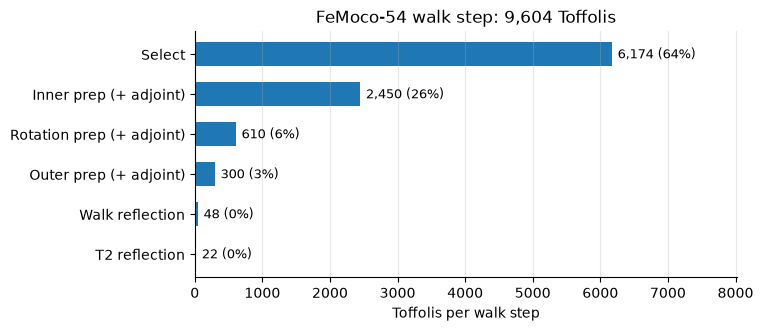

In [6]:
breakdown = df_cost.drop("Total").sort_values("toffolis_per_walk")

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(
    breakdown.index, breakdown["toffolis_per_walk"], color="tab:blue", height=0.6
)
ax.bar_label(
    bars,
    labels=[
        f"{v:,.0f} ({s:.0%})"
        for v, s in zip(breakdown["toffolis_per_walk"], breakdown["share"], strict=True)
    ],
    padding=4,
    fontsize=9,
)
ax.set_xlabel("Toffolis per walk step")
ax.set_xlim(0, breakdown["toffolis_per_walk"].max() * 1.3)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_title(f"FeMoco-54 walk step: {toffolis_per_walk:,} Toffolis")
plt.show()

A few things to notice:

- **Select dominates**, with about two thirds of the cost. Each call applies two Givens ladders of $N - 1 = 53$ rotations to the system register, each implemented as $b_{\mathrm{rot}}$-bit additions into the phase gradient register. Low et al. (2025) report that Select is about 60% of the cost for typical DFTHC solutions.
- **The inner prep is the second largest cost**, from its QROAM over $RC(B+1) = 7560$ entries. This is where the choice of $C$ matters: DFTHC picks $(R, B, C)$ so that this QROAM and the rotation QROM (over $RB = 270$ entries) are both much cheaper than Select.
- **Our total of 9,604 Toffolis agrees with the 9,997 of Table III to within 4%.** The largest difference is in Select: Low et al. charge $b_{\mathrm{rot}}$ Toffolis per phase gradient addition, four per Givens rotation and its inverse, while the Qualtran circuit uses $b_{\mathrm{rot}} - 1$, so $4(b_{\mathrm{rot}}-1) = 56$ instead of 60. Their other Table III entries are leading-order formulas, so small differences in the other subroutines are expected.
- Table V of Low et al. (2025) quotes $\mathrm{Cost}[\mathrm{BE}] = 10{,}203$ for the same molecule. That estimate uses the bits of precision from their Appendix D instead of the uniform 15 bits of Table III.

### Does the Hamiltonian data matter?

We used random factors, so it is worth checking that the Toffoli count doesn't depend on them. QUICHE currently loads two sets of data from the Hamiltonian:

- `rotation_data`: the Givens angles of the unit vectors, loaded by the rotation QROM for the squared-factor terms.
- `tail_data`: the Givens angles and the $G_1$ sign bits of the one-body terms, loaded by the tail of the inner QROM (`InnerQROMTail`).

The alias sampling tables (alt, keep, sign) are still placeholders. Below, we replace both data sets with placeholder data and compare the costs.

In [7]:
placeholder_walk = attrs.evolve(walk, rotation_data=None, tail_data=None)

real_cost = get_cost_value(walk, QECGatesCost())
placeholder_cost = get_cost_value(placeholder_walk, QECGatesCost())

print(f"{'':<14}{'Toffolis':>10}{'Cliffords':>12}")
print(f"{'Hamiltonian':<14}{toffoli_count(walk):>10,}{real_cost.clifford:>12,}")
print(
    f"{'Placeholder':<14}{toffoli_count(placeholder_walk):>10,}{placeholder_cost.clifford:>12,}"
)

                Toffolis   Cliffords
Hamiltonian        9,604     477,254
Placeholder        9,604     254,564


The Toffoli counts are identical. A QROM uses Toffolis to iterate over its entries, and writes each data bit with a CNOT, so the data only changes the Clifford count. This is why a dummy Hamiltonian is enough for the Toffoli count. The values of the factors only enter the total cost through $\Lambda$ and $E_{\mathrm{gap}}$.

## 6.6. Logical qubits

Low et al. (2025) report 1,131 logical qubits in Table III (1,132 in Table V). Most of them are the persistent output register of the rotation QROM, which holds $(N-1)\,b_{\mathrm{rot}} = 795$ bits of Givens angles. The QROAM in the inner prep reuses those qubits as temporary space before the rotation QROM writes to them.

In [8]:
num_qubits = get_cost_value(walk, QubitCount())
num_system = block_encoding.system_bitsize
num_phase_grad = block_encoding.resource_bitsize
num_ancilla = block_encoding.ancilla_bitsize
num_rotation_angles = (N - 1) * B_ROT
num_other = num_qubits - num_system - num_phase_grad - num_ancilla - num_rotation_angles

print(f"{'System (2N)':<34}{num_system:>6,}")
print(f"{'Phase gradient (b_rot)':<34}{num_phase_grad:>6,}")
print(f"{'Block-encoding ancillas':<34}{num_ancilla:>6,}")
print(f"{'Rotation angles ((N-1) b_rot)':<34}{num_rotation_angles:>6,}")
print(f"{'Other temporary ancillas':<34}{num_other:>6,}")
print(f"{'Total':<34}{num_qubits:>6,}")

System (2N)                          108
Phase gradient (b_rot)                15
Block-encoding ancillas               49
Rotation angles ((N-1) b_rot)        795
Other temporary ancillas             171
Total                              1,138


Our total of 1,138 qubits is within 1% of the 1,131 reported by Low et al. (2025).

## 6.7. Choosing the QROAM block sizes

The QROAM block size $2^k$ trades Toffolis against qubits. A QROAM over $L$ entries of $b$ bits costs about $\lceil L/2^k \rceil + (2^k - 1)\,b$ Toffolis and needs $(2^k - 1)\,b$ extra qubits. Uncomputation is cheaper, about $\lceil L/2^k \rceil + 2^k$, because it is measurement-based, so its optimal block size is different.

We vary each of $k_1, k_2, k_4, k_5$ in turn, with the others fixed at the values from Section 6.2. This takes about a minute.

In [9]:
BLOCK_SIZES = {
    "log_block_size_outer": ("$k_1$ (outer QROAM)", range(6)),
    "log_block_size_inner": (
        "$k_2$ (inner QROAM)",
        range(1, 5),
    ),  # k_2 < ceil(log2(B + 1))
    "log_block_size_inner_adjoint": ("$k_4$ (inner QROAM$^\\dagger$)", range(6)),
    "log_block_size_outer_adjoint": ("$k_5$ (outer QROAM$^\\dagger$)", range(7)),
}


def scan_block_size(param: str, values: range) -> list[dict[str, Any]]:
    """Toffolis and qubits of the walk operator as one block size varies."""
    rows = []
    for k in values:
        bloq = attrs.evolve(placeholder_walk, **{param: k})
        rows.append(
            {
                "param": param,
                "k": k,
                "toffolis": toffoli_count(bloq),
                "qubits": get_cost_value(bloq, QubitCount()),
            }
        )
    return rows


df_scan = pd.DataFrame(
    [
        row
        for param, (_, values) in BLOCK_SIZES.items()
        for row in scan_block_size(param, values)
    ]
)

# One row per block size, with "Toffolis (qubits)" for each parameter.
df_scan["cell"] = [
    f"{t:,} ({q:,})"
    for t, q in zip(df_scan["toffolis"], df_scan["qubits"], strict=True)
]
df_scan.pivot_table(index="k", columns="param", values="cell", aggfunc="first")[
    list(BLOCK_SIZES)
].rename(
    columns={
        "log_block_size_outer": "k_1",
        "log_block_size_inner": "k_2",
        "log_block_size_inner_adjoint": "k_4",
        "log_block_size_outer_adjoint": "k_5",
    }
).fillna("")

param,k_1,k_2,k_4,k_5
k,,,,
0,"9,775 (1,066)",,"9,840 (1,138)","9,892 (1,138)"
1,"9,637 (1,090)","15,512 (1,138)","9,626 (1,138)","9,731 (1,138)"
2,"9,604 (1,138)","11,816 (1,138)","9,604 (1,138)","9,652 (1,138)"
3,"9,660 (1,234)","10,348 (1,138)","9,760 (1,138)","9,616 (1,138)"
4,"9,832 (1,426)","9,604 (1,138)","10,174 (1,138)","9,604 (1,138)"
5,"10,206 (1,810)",,"11,054 (1,172)","9,610 (1,138)"
6,,,,"9,637 (1,138)"


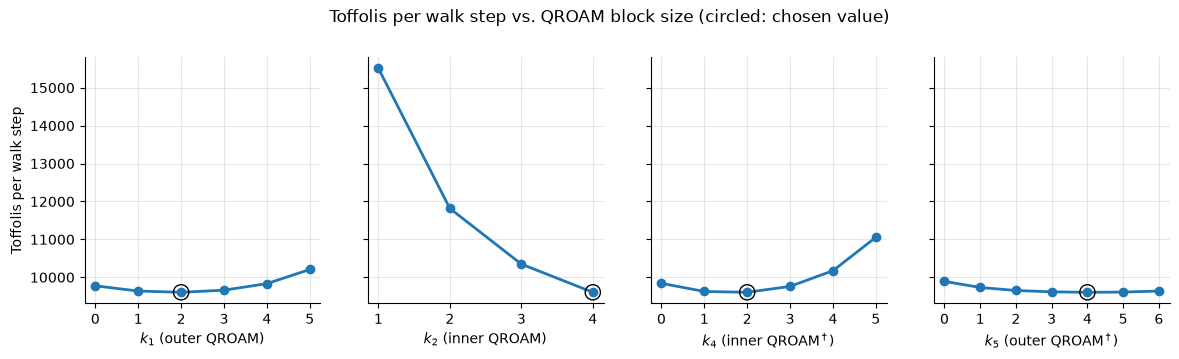

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, (param, (label, _)) in zip(axes, BLOCK_SIZES.items(), strict=True):
    data = df_scan[df_scan["param"] == param]
    chosen = data[data["k"] == walk_kwargs[param]]
    ax.plot(data["k"], data["toffolis"], marker="o", color="tab:blue", linewidth=2)
    ax.scatter(
        chosen["k"],
        chosen["toffolis"],
        s=120,
        facecolors="none",
        edgecolors="black",
        zorder=3,
    )
    ax.set_xlabel(label)
    ax.set_xticks(data["k"])
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Toffolis per walk step")
fig.suptitle(
    "Toffolis per walk step vs. QROAM block size (circled: chosen value)", y=1.03
)
plt.show()

A few things to notice:

- **The inner QROAM ($k_2$) matters most.** Going from $k_2 = 1$ to $k_2 = 4$ saves almost 6,000 Toffolis per step (about 40%), because its table of $RC(B+1) = 7560$ entries is by far the largest. Its temporary qubits are free, since they reuse the 795-qubit rotation register. $k_2$ is limited to 4 by the number of bits of the inner index $b$.
- **The outer QROAM ($k_1$)** has a shallow minimum at $k_1 = 2$. Beyond it, the qubit count grows quickly (from 1,138 to 1,810 at $k_1 = 5$) and the Toffoli count goes up again, because the outer table only has $N + RC = 324$ entries.
- **The uncomputations ($k_4$, $k_5$)** have flat minima. Measurement-based uncomputation doesn't increase the total qubit count for any $k_5$, and for $k_4$ only from $k_4 = 5$.
- The values from Table III of Low et al. (2025), $(k_1, k_2, k_4, k_5) = (2, 4, 2, 4)$, are optimal along each of these scans.

## 6.8. Total Toffoli count for phase estimation

Now we combine the cost per walk step with the number of walk steps. We take $\Lambda$ and $E_{\mathrm{gap}}$ for FeMoco-54 from Table V of Low et al. (2025), since they depend on the real factorisation.

In [11]:
# FeMoco-54 DFTHC + BLISS normalisation and SOS gap ([Low2025], Table V).
LAMBDA = 58.3440  # Hartree
E_GAP = 4.0535  # Hartree
PAPER_COST_BE = 10_203  # Toffolis per walk step
PAPER_TOTAL = 3.42e8  # Toffolis

lambda_eff = np.sqrt(E_GAP * (2 * LAMBDA - E_GAP))


def num_walk_calls(lam: float, sigma: float = SIGMA_PEA) -> int:
    """Count the walk steps to estimate the energy with standard deviation sigma."""
    return int(np.ceil(np.pi * lam / (2 * sigma)))


num_calls = num_walk_calls(lambda_eff)
total_toffolis = num_calls * toffolis_per_walk

print(f"Lambda          {LAMBDA:>14.4f} Ha")
print(f"E_gap           {E_GAP:>14.4f} Ha")
print(f"lambda_eff      {lambda_eff:>14.4f} Ha")
print(f"Walk steps      {num_calls:>14,}")
print(f"Toffolis/step   {toffolis_per_walk:>14,}")
print(f"Total Toffolis  {total_toffolis:>14.3e}")
print(f"Logical qubits  {num_qubits:>14,}")
print()
print(f"Low et al. Cost[BE] x walk steps: {num_calls * PAPER_COST_BE:.3e}")
print(f"Low et al. total (Table V):       {PAPER_TOTAL:.2e}")

Lambda                 58.3440 Ha
E_gap                   4.0535 Ha
lambda_eff             21.3674 Ha
Walk steps              33,564
Toffolis/step            9,604
Total Toffolis       3.223e+08
Logical qubits           1,138

Low et al. Cost[BE] x walk steps: 3.425e+08
Low et al. total (Table V):       3.42e+08


Our estimate of $3.2\times10^{8}$ Toffolis is 6% below the $3.42\times10^{8}$ of Low et al. (2025), entirely because of the lower cost per walk step. With their $\mathrm{Cost}[\mathrm{BE}]$, the same formula reproduces their total.

To see where the improvement over previous work comes from, we compute the total with the same formula for the best previous DF and THC block encodings of FeMoco-54, using $\lambda$ and $\mathrm{Cost}[\mathrm{BE}]$ from Table V of Low et al. (2025). We also include an intermediate row: the DFTHC walk step, but with the normalisation $\Lambda$ in place of $\lambda_{\mathrm{eff}}$, to separate the gain from the factorisation from the gain from spectral amplification.

In [12]:
METHODS = [
    # (method, lambda in Ha, Toffolis per walk step, logical qubits)
    ("THC (Lee et al. 2021)", 306.30, 11_016, 2142),
    ("Symmetry-compressed DF (Rocca et al. 2024)", 78.00, 19_589, 3722),
    ("DFTHC + BLISS, without SA", LAMBDA, toffolis_per_walk, num_qubits),
    ("DFTHC + BLISS + SA (this notebook)", lambda_eff, toffolis_per_walk, num_qubits),
]

df_methods = pd.DataFrame(
    METHODS, columns=["method", "lambda", "toffolis_per_walk", "qubits"]
)
df_methods["walk_steps"] = df_methods["lambda"].map(num_walk_calls)
df_methods["total_toffolis"] = (
    df_methods["walk_steps"] * df_methods["toffolis_per_walk"]
)
df_methods["improvement"] = (
    df_methods["total_toffolis"].iloc[0] / df_methods["total_toffolis"]
)
df_methods.set_index("method").style.format(
    {
        "lambda": "{:.2f}",
        "toffolis_per_walk": "{:,}",
        "qubits": "{:,}",
        "walk_steps": "{:,}",
        "total_toffolis": "{:.2e}",
        "improvement": "{:.1f}x",
    }
)

,lambda,toffolis_per_walk,qubits,walk_steps,total_toffolis,improvement
method,,,,,,
THC (Lee et al. 2021),306.30,"11,016","2,142","481,135",5.30e+09,1.0x
Symmetry-compressed DF (Rocca et al. 2024),78.00,"19,589","3,722","122,523",2.40e+09,2.2x
"DFTHC + BLISS, without SA",58.34,"9,604","1,138","91,647",8.80e+08,6.0x
DFTHC + BLISS + SA (this notebook),21.37,"9,604","1,138","33,564",3.22e+08,16.4x


A few things to notice:

- **The factorisation and the spectral amplification contribute separately.** Compared with THC, DFTHC + BLISS has a normalisation that is about $5\times$ smaller with a similar cost per step. Spectral amplification then reduces the effective normalisation by another factor of $\Lambda/\lambda_{\mathrm{eff}} \approx 2.7$.
- **Spectral amplification works because the gap is small.** $\lambda_{\mathrm{eff}} \approx \sqrt{2\Lambda E_{\mathrm{gap}}}$, and here $E_{\mathrm{gap}} = 4.05$ Ha is only 7% of $\Lambda = 58.3$ Ha. A sum-of-squares representation with a larger gap would benefit less.
- **The walk step is cheap, but needs many of them.** Each step costs only about $10^4$ Toffolis, but phase estimation needs about $3.4\times10^{4}$ steps for 1 mHa precision. The number of steps scales as $1/\sigma_{\mathrm{PEA}}$, so halving the target error doubles the cost.
- The comparison uses $\mathrm{Cost}[\mathrm{BE}]$ values from the literature for DF and THC, which come from different circuit constructions and cost models. Treat the improvement factors as indicative, as Low et al. do. Our $16.4\times$ over THC is slightly larger than the $15.5\times$ in their Table V, because our walk step is cheaper.

## 6.9. Physical resources

Finally, as in tutorial 4, we convert the logical costs into surface code costs with Qualtran's grid search over code distances and magic state factories.

In [13]:
physical_cost, factory, data_block = get_ccz2t_costs_from_grid_search(
    n_logical_gates=GateCounts(toffoli=total_toffolis),
    n_algo_qubits=num_qubits,
    phys_err=PHYS_ERR,
    error_budget=PHYS_ERROR_BUDGET,
    cycle_time_us=CYCLE_TIME_US,
)

print(f"Physical qubits  {physical_cost.footprint:>12,}")
print(f"Runtime          {physical_cost.duration_hr:>12.1f} hours")
print(f"Failure prob.    {physical_cost.failure_prob:>12.4f}")
print(f"Data block       {data_block}")
print(f"Factory          {factory}")

Physical qubits     3,431,830
Runtime                  17.2 hours
Failure prob.          0.0046
Data block       SimpleDataBlock(data_d=31, routing_overhead=0.5)
Factory          CCZ2TFactory(distillation_l1_d=17, distillation_l2_d=25)


With a physical error rate of $10^{-3}$ and a 1 µs cycle time, the calculation needs about 3.4 million physical qubits and runs in about 17 hours. This model distils one CCZ state at a time with a single factory, so the runtime is set by the Toffoli count. These numbers depend strongly on the hardware assumptions and on the layout, and are only a rough guide.

## 6.10. Takeaways

- **The pipeline**: `DFTHCHamiltonian` (or `quiche.io.dfthc_db.read` for a real factorisation) → `DFTHCWalkOperator.from_dfthc_hamiltonian` → Qualtran gate counts → Toffolis per walk step → $\lceil\pi\lambda_{\mathrm{eff}}/(2\sigma_{\mathrm{PEA}})\rceil$ walk steps → total Toffolis.
- **QUICHE reproduces the FeMoco-54 block encoding of Low et al.** to within 4% in Toffolis (9,604 vs. 9,997 per walk step) and 1% in logical qubits (1,138 vs. 1,131), and the total cost to within 6% ($3.2\times10^{8}$ vs. $3.42\times10^{8}$ Toffolis).
- **Select is the bottleneck** at about two thirds of each walk step, and the inner QROAM block size $k_2$ is the most important circuit parameter to tune.
- **The Toffoli count of a walk step depends only on the shape** $(N, R, B, C)$ and on the circuit parameters, not on the values of the factors. The values enter through $\Lambda$ and $E_{\mathrm{gap}}$.

These results come with some caveats:

- $\Lambda$ and $E_{\mathrm{gap}}$ were taken from Low et al. (2025), because QUICHE doesn't compute them from a `DFTHCHamiltonian` yet. A real estimate needs the optimised factors, and a check that their factorisation error is within the error budget, which Low et al. do with CCSD(T) correlation energies.
- We used 15 bits for every precision parameter, as in Table III. Appendix D of Low et al. (2025) chooses the bits per system, which changes the cost per walk step slightly.
- We ignored the 12 small arbitrary-angle rotations per walk step in the uniform state preparations.
- The total assumes that the initial state has perfect overlap with the ground state, as in Low et al. (2025). With overlap $p < 1$, phase estimation must be repeated about $1/p$ times.